# Tutorial 4 - Mouse stroke: a 2D and a 3D counterfactual prediction

Photothrombotic stroke in mouse cortex. Four sections were taken from each animal, and the
sections of one animal are registered into a shared frame, so a lesion learned on a stroke animal
can be **imposed on a sham animal** and the prediction placed beside the real lesion in the
stroke animal.

### What is being predicted

The lesion has two compartments, and the model is given them as two **separate perturbation
labels**:

* **ICA** - the ischaemic core
* **PIA** - the peri-infarct area, the rim around it

The counterfactual is: *take a healthy (sham) brain, impose a lesion of the same shape, size and
per-section extent as the real one, and predict what each spot's expression becomes.* The
measured stroke animal carries the real lesion in the same coordinate frame.

### The two arms

| arm | footprint field | what it can express |
|---|---|---|
| `stroke_2d_core_rim` | `(x, y)`, sections superimposed | one spatial field shared by the four sections |
| `stroke_3d_core_rim` | `(x, y, ordinal section)` | a field that can differ between sections |

Both are trained with the sections tiled **by animal**, which puts the four sections of one
animal in a common frame. The 3D arm adds the section index as a third coordinate of the
footprint field (`--fpert_n_z_levels 4` against `1` for the 2D arm; every other setting is
shared).

### What the notebook does

1. resolve paths
2. explain the three decode passes and the per-compartment assembly
3. optionally re-run those passes on a GPU; otherwise read the shipped decodes
4. assemble the predicted induction and load the measured stroke animal
5. draw the predicted lesion maps beside the measured ones, for both arms

## 0. Before you start

Every section except 3 is **CPU-only**: it reads the shipped decode outputs and draws. Section 3,
which re-runs the decodes, needs a GPU (about 20 minutes per arm on one H100).

```bash
# one GPU node from your scheduler, then start Jupyter inside it
conda activate concert_env        # built from env_requirements.txt (main README, "Run CONCERT")
# data/ and checkpoints/ sit in the repository root (or set CONCERT_DATA_DIR / CONCERT_CHECKPOINT_ROOT)
jupyter lab --no-browser --ip=0.0.0.0
```

## 1. Paths

The section coordinates are **registered** before CONCERT sees them: `prepare_slides.py` reads a
PASTE2 alignment from the registration delivery and writes it into the slide files. Overlap
between paired sections ranges from about 0.3 to 0.8.

In [1]:
import warnings, logging
warnings.filterwarnings("ignore")   # anndata/scanpy FutureWarning and library chatter
for _lib in ("anndata", "scanpy", "matplotlib", "numba", "torch", "h5py", "fontTools", "py.warnings"):
    logging.getLogger(_lib).setLevel(logging.ERROR)

import os, sys, json, subprocess
from pathlib import Path

# The repository root: the directory holding models/ and benchmark_evaluation/. Found by
# walking up from the working directory, so the notebook runs from anywhere inside the repo;
# set CONCERT_CODEBASE to override. Every other root below reads an environment variable too,
# with the paths these results were produced on as the fallback -- see datasets/README.md.
def _repo_root():
    env = os.environ.get("CONCERT_CODEBASE")
    if env:
        return Path(env)
    for d in [Path.cwd(), *Path.cwd().parents]:
        if (d / "models" / "concert_benchmark").is_dir():
            return d
    raise RuntimeError("cannot locate the repository root; set CONCERT_CODEBASE")

def _root(var, default):
    return Path(os.environ.get(var, default))

CODEBASE  = _repo_root()
MODEL_SRC = CODEBASE / "models" / "concert_spac_niche"      # the copy that produced these results
EXP       = CODEBASE / "experiments" / "07_stroke_case_study"

# Every input sits in the downloadable data/ and checkpoints/ folders; release_paths.py defines
# their layout and reads CONCERT_DATA_DIR and CONCERT_CHECKPOINT_ROOT.
sys.path.insert(0, str(CODEBASE / "benchmark_evaluation"))
import release_paths as rp

SLIDES  = rp.STROKE / "slides"                               # the compartment-labelled slides
ARM_DIR = {"2d": rp.CHECKPOINTS / "stroke_2d_core_rim", "3d": rp.CHECKPOINTS / "stroke_3d_core_rim"}
DECODES = {"2d": rp.STROKE / "decodes_2d", "3d": rp.STROKE / "decodes_3d"}   # shipped decodes

# region labels of the measured stroke animal (ICA / PIA), from the registration delivery
REGION_H5 = rp.STROKE / "Mouse_brain_stroke_all_data.h5"

WORKDIR = Path(os.environ.get(
    "CONCERT_NB_WORKDIR",
    f"{rp.WORKDIR}/notebook_runs/04_stroke"))
WORKDIR.mkdir(parents=True, exist_ok=True)

STACKS = ["PT", "Sham"]          # PT = photothrombosis (real lesion), Sham = healthy control

checks = [("model source",        MODEL_SRC / "run_concert_spac.py"),
          ("figure code",         EXP / "figures" / "plot_core_rim_patch.py"),
          ("slides (sham 1)",     SLIDES / "stroke_paste2_Sham1.h5ad"),
          ("slides (stroke 1)",   SLIDES / "stroke_paste2_PT1.h5ad"),
          ("region labels",       REGION_H5)]
for arm, d in ARM_DIR.items():
    checks += [(f"{arm} checkpoint",   d / "model.pt"),
               (f"{arm} gene axis",    d / "hvg_gene_names.txt"),
               (f"{arm} lesion shape", d / "shape_sets" / "shape_core_local.txt"),
               (f"{arm} sham index",   d / "sham_cells.json"),
               (f"{arm} shipped stats", d / f"figure_stats_patch_{arm}_cr.json")]
for label, p in checks:
    print(f"{'OK ' if p.exists() else 'MISSING':>8}  {label:<20}  {rp.show(p)}")
print(f"\nnotebook output dir: {rp.show(WORKDIR)}")

     OK   model source          <repo>/models/concert_spac_niche/run_concert_spac.py
     OK   figure code           <repo>/experiments/07_stroke_case_study/figures/plot_core_rim_patch.py
     OK   slides (sham 1)       $CONCERT_DATA_DIR/stroke/slides/stroke_paste2_Sham1.h5ad
     OK   slides (stroke 1)     $CONCERT_DATA_DIR/stroke/slides/stroke_paste2_PT1.h5ad
     OK   region labels         $CONCERT_DATA_DIR/stroke/Mouse_brain_stroke_all_data.h5
     OK   2d checkpoint         $CONCERT_CHECKPOINT_ROOT/stroke_2d_core_rim/model.pt
     OK   2d gene axis          $CONCERT_CHECKPOINT_ROOT/stroke_2d_core_rim/hvg_gene_names.txt
     OK   2d lesion shape       $CONCERT_CHECKPOINT_ROOT/stroke_2d_core_rim/shape_sets/shape_core_local.txt
     OK   2d sham index         $CONCERT_CHECKPOINT_ROOT/stroke_2d_core_rim/sham_cells.json
     OK   2d shipped stats      $CONCERT_CHECKPOINT_ROOT/stroke_2d_core_rim/figure_stats_patch_2d_cr.json
     OK   3d checkpoint         $CONCERT_CHECKPOINT_ROOT/strok

## 2. The counterfactual: three decode passes

The same cells are decoded three times, differing **only** in the perturbation attribute:

| pass | perturbation | applied to |
|---|---|---|
| `oncore` | `ICA` | the imposed **core** spots |
| `onrim` | `PIA` | the imposed **rim** spots |
| `off` | `__basal__` | every sham spot - the matched control |

The predicted induction is then assembled per compartment:

```
delta[core] = oncore[core] - off[core]
delta[rim]  = onrim[rim]  - off[rim]
```

**This assembly is exact.** The niche descriptor builds a spot's microenvironment code from the
expression latent and the coordinates only, so a core spot's decode is the same whether or not
the rim spots were switched on in the same pass.

The imposed geometry is fixed by three index files under `shape_sets/`, transferred from the real
lesion so shape, size and per-section extent match:

* `shape_lesion_local.txt` - every spot inside the imposed lesion
* `shape_core_local.txt` - the core subset
* `shape_rim_local.txt` - the rim subset

(`_local` indexes the sham stack; the un-suffixed files index all eight slides and are what the
decode command is given.)

## 3. Running the decodes

`--stage eval` loads `<outdir>/model.pt`, so the output directory has to contain the checkpoint.
As in tutorial 3, the cell builds a **symlink shadow** of the arm directory under `WORKDIR` and
writes there.

`RUN_DECODE` is off by default; the shipped decode outputs are read.

In [2]:
RUN_DECODE = False        # True -> re-run the three passes for RUN_ARMS on a GPU
RUN_ARMS   = ["2d"]       # ["2d", "3d"] for both (about 20 min per arm)

SLIDE_FILES = ",".join(str(SLIDES / f"stroke_paste2_{s}{i}.h5ad")
                       for s in STACKS for i in (1, 2, 3, 4))
PASSES = [("oncore", "ICA",       "shape_core.txt"),
          ("onrim",  "PIA",       "shape_rim.txt"),
          ("off",    "__basal__", None)]              # None -> every sham spot

def decode_cmd(arm, shadow, pass_name, target, cells_file):
    nz = {"2d": "1", "3d": "4"}[arm]
    return [
        sys.executable, "-u", "run_concert_spac.py", "--stage", "eval",
        "--config", "config.yaml", "--sample", f"stroke_{arm}_cr_{pass_name}",
        "--multi_sample_files", SLIDE_FILES,
        "--outdir", str(shadow), "--model_file", "model.pt", "--project_index", "stroke",
        "--hvg_max_rank", "2000", "--seed", "42",
        "--unassigned_label", "unperturbed", "--control_label", "__NONE__",
        "--min_cells_per_pert", "25",
        "--use_action_correction", "False", "--use_pad", "False",
        "--inducing_point_steps", "6", "--grid_inducing_points", "True",
        "--loc_range", "20.0", "--kernel_scale", "10.0", "--multi_kernel_mode", "True",
        "--use_expr_encoder", "True", "--expr_hidden_dims", "512", "256",
        "--use_basal_encoder_only", "True",
        "--dynamicVAE", "False", "--free_bits", "0.5", "--gp_free_bits", "1.0",
        "--use_nngp", "False", "--use_paracrine", "False",
        "--use_niche_interaction", "False", "--use_niche_film", "True",
        "--niche_film_dim", "8", "--niche_film_k", "25",
        "--niche_film_gcap", "3.0", "--niche_film_l2", "1e-3",
        "--use_pert_gate", "True", "--gate_hidden", "64",
        "--use_f_pert", "True", "--f_pert_clamp", "5.0",
        "--spatial_basal_only", "True", "--lfc_ref_tissue", "CTX",
        "--basal_field", "rff", "--basal_bayes", "True",
        "--moran_lambda", "1.0", "--disentangle_radius", "4.0",
        "--fpert_field", "gp_pp", "--fpert_coord_scale", "20.0",
        "--fpert_rff_features", "128", "--fpert_rff_bandwidth", "0.15",
        "--fpert_ls_min", "0.05", "--fpert_ls_max", "0.60",
        "--tile_by_stack", "True", "--z_stack_obs", "mouse",
        "--z_index_obsm", "section_index",
        "--fpert_n_z_levels", nz, "--fpert_z_gain", "0.25",
        "--ls_prior_lambda", "1.0", "--ls_prior_min", "3", "--ls_prior_max", "18",
        "--fpert_svgp_inducing", "16", "--fpert_svgp_ls_init", "5.0",
        "--pert_cells", str(cells_file),
        "--target_cell_tissue", "CTX", "--target_cell_perturbation", target,
        "--verbosity", "1",
    ]

SHADOW = {}
for arm in ARM_DIR:
    sh = WORKDIR / f"{arm}_shadow"
    sh.mkdir(parents=True, exist_ok=True)
    for f in ARM_DIR[arm].iterdir():                 # checkpoint + geometry + sidecar files
        tgt = sh / f.name
        if not tgt.exists():
            tgt.symlink_to(f)
    SHADOW[arm] = sh

if RUN_DECODE:
    for arm in RUN_ARMS:
        for pass_name, target, shape_file in PASSES:
            cells_file = (SHADOW[arm] / "shape_sets" / shape_file) if shape_file \
                         else (SHADOW[arm] / "sham_cells.txt")
            print(f"\n=== {arm} / {pass_name}: {target} on {cells_file.name} ===")
            r = subprocess.run(decode_cmd(arm, SHADOW[arm], pass_name, target, cells_file),
                               cwd=str(MODEL_SRC))
            print("exit code", r.returncode)
else:
    print("RUN_DECODE is False -- the shipped decodes are read below.\n")
    for arm in ARM_DIR:
        got = sorted(p.name for p in DECODES[arm].glob("*_perturbed_counts.h5ad"))
        print(f"{arm}: {len(got)} decode outputs on disk")
        for g in got[:4]:
            print("   ", g)

RUN_DECODE is False -- the shipped decodes are read below.

2d: 8 decode outputs on disk
    stroke_2d_cr_off_stroke_CTX___basal___perturbed_counts.h5ad
    stroke_2d_cr_oncore_stroke_CTX_ICA_perturbed_counts.h5ad
    stroke_2d_cr_onrim_obs_stroke_CTX_PIA_perturbed_counts.h5ad
    stroke_2d_cr_onrim_stroke_CTX_PIA_perturbed_counts.h5ad
3d: 8 decode outputs on disk
    stroke_3d_cr_off_stroke_CTX___basal___perturbed_counts.h5ad
    stroke_3d_cr_oncore_stroke_CTX_ICA_perturbed_counts.h5ad
    stroke_3d_cr_onrim_obs_stroke_CTX_PIA_perturbed_counts.h5ad
    stroke_3d_cr_onrim_stroke_CTX_PIA_perturbed_counts.h5ad


## 4. Assemble the predicted induction

Each decode writes one `*_perturbed_counts.h5ad` holding all eight slides in file order. Two
bookkeeping steps turn those into a per-compartment induction map:

1. **select the sham rows.** `sham_cells.json` records the per-file cell counts and which files
   belong to the sham animal, which gives the row block to keep.
2. **put the counts on a common scale.** Both sides are shown as `log1p` of counts per 10,000.

The measured side is the stroke animal's own expression, with its region labels (ICA / PIA) from
the registration delivery.

In [3]:
import numpy as np
import anndata as ad, h5py, pandas as pd

def log1p_cpm(X):
    s = X.sum(1, keepdims=True); s[s == 0] = 1.0
    return np.log1p(X / s * 1e4)

def load_stack(stack):
    ps = sorted(SLIDES.glob(f"stroke_paste2_{stack}*.h5ad"))
    A = ad.concat([ad.read_h5ad(p) for p in ps], label="sf", keys=[p.stem for p in ps],
                  index_unique=None)
    section = np.unique(np.asarray(A.obsm["section_index"]).reshape(-1), return_inverse=True)[1]
    return A, np.asarray(A.obsm["array_coords"], np.float32), section

def norm_xy(xy):
    lo, hi = xy.min(0), xy.max(0)
    return (xy - lo) / np.maximum(hi - lo, 1e-8)

def build_delta(arm, source_dir=None):
    """Predicted induction per spot on the sham animal, assembled per compartment."""
    d = Path(source_dir or DECODES[arm])
    side = json.loads((d / "sham_cells.json").read_text())
    offsets = np.concatenate([[0], np.cumsum(side["counts"])])[:-1]
    rows = np.concatenate([np.arange(o, o + c)
                           for o, c, t in zip(offsets, side["counts"], side["is_target"]) if t])
    def read(pass_name):
        # The `_stroke_` segment is load-bearing: the arm directories also hold decodes from
        # the rim-thickness and observed-shape variants, named `onrim_obs_*`, `onrim_t1_*` and
        # so on. A looser glob picks one of those instead, in an order that is not defined.
        hits = sorted(d.glob(f"stroke_{arm}_cr_{pass_name}_stroke_*_perturbed_counts.h5ad"))
        if len(hits) != 1:
            raise FileNotFoundError(f"expected one {pass_name} decode in {d}, found {hits}")
        return log1p_cpm(np.asarray(ad.read_h5ad(hits[0]).X[rows], np.float32))
    L_core, L_rim, L_off = read("oncore"), read("onrim"), read("off")

    genes = np.loadtxt(d / "hvg_gene_names.txt", dtype=str)
    n_sham = L_off.shape[0]
    inside = lambda f: np.isin(np.arange(n_sham), np.loadtxt(d / "shape_sets" / f, dtype=np.int64))
    p_in   = inside("shape_lesion_local.txt")
    p_core = inside("shape_core_local.txt") & p_in
    p_rim  = inside("shape_rim_local.txt") & p_in

    delta = np.zeros_like(L_off)
    delta[p_core] = L_core[p_core] - L_off[p_core]
    delta[p_rim]  = L_rim[p_rim]  - L_off[p_rim]
    return dict(delta=delta, genes=genes, in_lesion=p_in, core=p_core, rim=p_rim)

PRED = {arm: build_delta(arm) for arm in ARM_DIR}
for arm, p in PRED.items():
    print(f"{arm}: {p['delta'].shape[0]} sham spots x {p['delta'].shape[1]} genes; "
          f"imposed lesion {int(p['in_lesion'].sum())} spots "
          f"({int(p['core'].sum())} core, {int(p['rim'].sum())} rim)")

2d: 9194 sham spots x 2000 genes; imposed lesion 1357 spots (375 core, 982 rim)
3d: 9194 sham spots x 2000 genes; imposed lesion 1357 spots (375 core, 982 rim)


In [4]:
# the measured side: the stroke animal, and its region labels
A_pt,  xy_pt,  sec_pt  = load_stack("PT")
A_sh,  xy_sh,  sec_sh  = load_stack("Sham")
L_pt   = log1p_cpm(np.asarray(A_pt.X.todense(), np.float32))
genes_obs = np.asarray(A_pt.var_names)

with h5py.File(REGION_H5, "r") as f:
    bc  = np.array([b.decode() for b in f["Barcode"][:]])
    reg = np.array([b.decode() for b in f["Celltype_coarse"][:]])
region = pd.Series(reg, index=bc).loc[np.asarray(A_pt.obs_names)].to_numpy()
o_core, o_rim = region == "ICA", region == "PIA"
o_in = o_core | o_rim

print(f"stroke animal: {A_pt.n_obs} spots over {sec_pt.max() + 1} sections; "
      f"measured lesion {int(o_in.sum())} spots ({int(o_core.sum())} ICA, {int(o_rim.sum())} PIA)")
print(f"sham animal  : {A_sh.n_obs} spots over {sec_sh.max() + 1} sections")

stroke animal: 10583 spots over 4 sections; measured lesion 1550 spots (472 ICA, 1078 PIA)
sham animal  : 9194 spots over 4 sections


## 5. Predicted beside measured

Each figure has two rows: the measured expression in the stroke animal, and the predicted
induction on the sham animal.

The examples are two injury markers, **Lcn2** and **Lgals1**. The 2D arm treats each section on
its own, so it is drawn for one section; the 3D arm is drawn for all four.

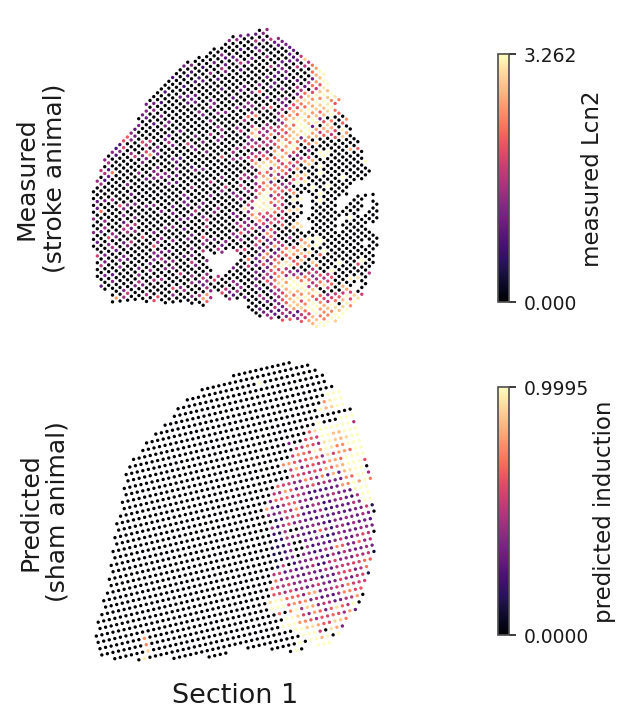

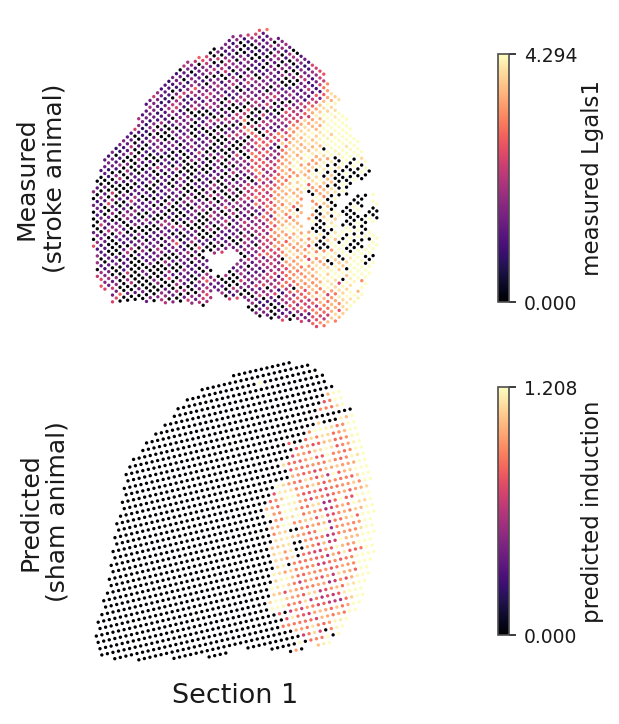

In [5]:
import matplotlib
sys.path.insert(0, str(CODEBASE / "experiments" / "03_dss_gut_case_study" / "figures"))
import paper_style as ps
ps.use()
# paper_style selects the Agg backend on import; switch back so the figures draw here.
%matplotlib inline
import matplotlib.pyplot as plt
npt, nsh = norm_xy(xy_pt), norm_xy(xy_sh)

def spatial_figure(arm, gene, sections=None):
    P = PRED[arm]
    if gene not in set(genes_obs.tolist()) or gene not in set(P["genes"].tolist()):
        raise KeyError(f"{gene} is not on both gene axes")
    ov = L_pt[:, int(np.where(genes_obs == gene)[0][0])]           # measured expression
    pv = P["delta"][:, int(np.where(P["genes"] == gene)[0][0])]    # predicted induction
    keep = sections if sections is not None else list(range(int(sec_pt.max()) + 1))

    vo, vp = np.quantile(ov, [.03, .97]), np.quantile(pv, [.03, .97])

    fig, ax = plt.subplots(2, len(keep), figsize=(2.5 * len(keep) + 2.0, 5.0), squeeze=False)
    for ci, s in enumerate(keep):
        mp, ms = sec_pt == s, sec_sh == s
        h0 = ax[0, ci].scatter(npt[mp, 0], npt[mp, 1], c=ov[mp], s=2.6, lw=0,
                               cmap=ps.FIELD_CMAP, vmin=vo[0], vmax=vo[1], rasterized=True)
        h1 = ax[1, ci].scatter(nsh[ms, 0], nsh[ms, 1], c=pv[ms], s=2.6, lw=0,
                               cmap=ps.FIELD_CMAP, vmin=vp[0], vmax=vp[1], rasterized=True)
        for r in range(2):
            ax[r, ci].set_xticks([]); ax[r, ci].set_yticks([])
            ax[r, ci].set_aspect("equal"); ax[r, ci].grid(False)
            for sp in ax[r, ci].spines.values():
                sp.set_visible(False)
        ax[1, ci].set_xlabel(f"Section {s + 1}", fontsize=13)
    for r, lab in enumerate(["Measured\n(stroke animal)", "Predicted\n(sham animal)"]):
        ax[r, 0].set_ylabel(lab, fontsize=12, labelpad=6)
    fig.subplots_adjust(wspace=0.02, hspace=0.02, left=0.12, right=0.87, top=0.98, bottom=0.10)
    for h, arow, lb in ((h0, ax[0, -1], f"measured {gene}"), (h1, ax[1, -1], "predicted induction")):
        po = arow.get_position(); pad = 0.12 * po.height
        cax = fig.add_axes([0.885, po.y0 + pad, 0.016, po.height - 2 * pad])
        cb = fig.colorbar(h, cax=cax); cb.set_label(lb, fontsize=11, labelpad=2)
        cb.ax.tick_params(labelsize=9); cb.set_ticks([cb.vmin, cb.vmax])
    return fig

# two injury markers: Lcn2 (rim-high) and Lgals1
SPATIAL_GENES = ["Lcn2", "Lgals1"]
for gene in SPATIAL_GENES:
    spatial_figure("2d", gene, sections=[0]); plt.show()

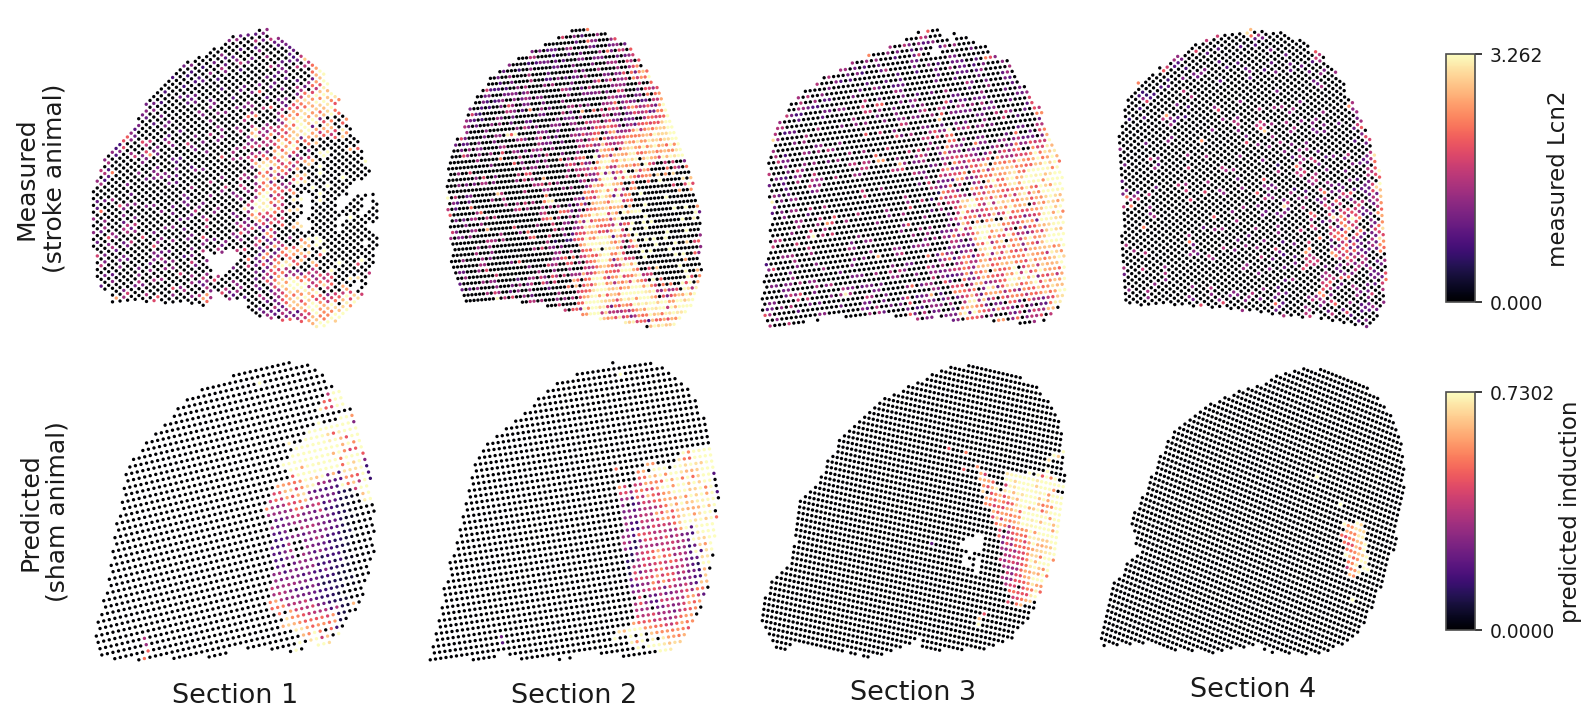

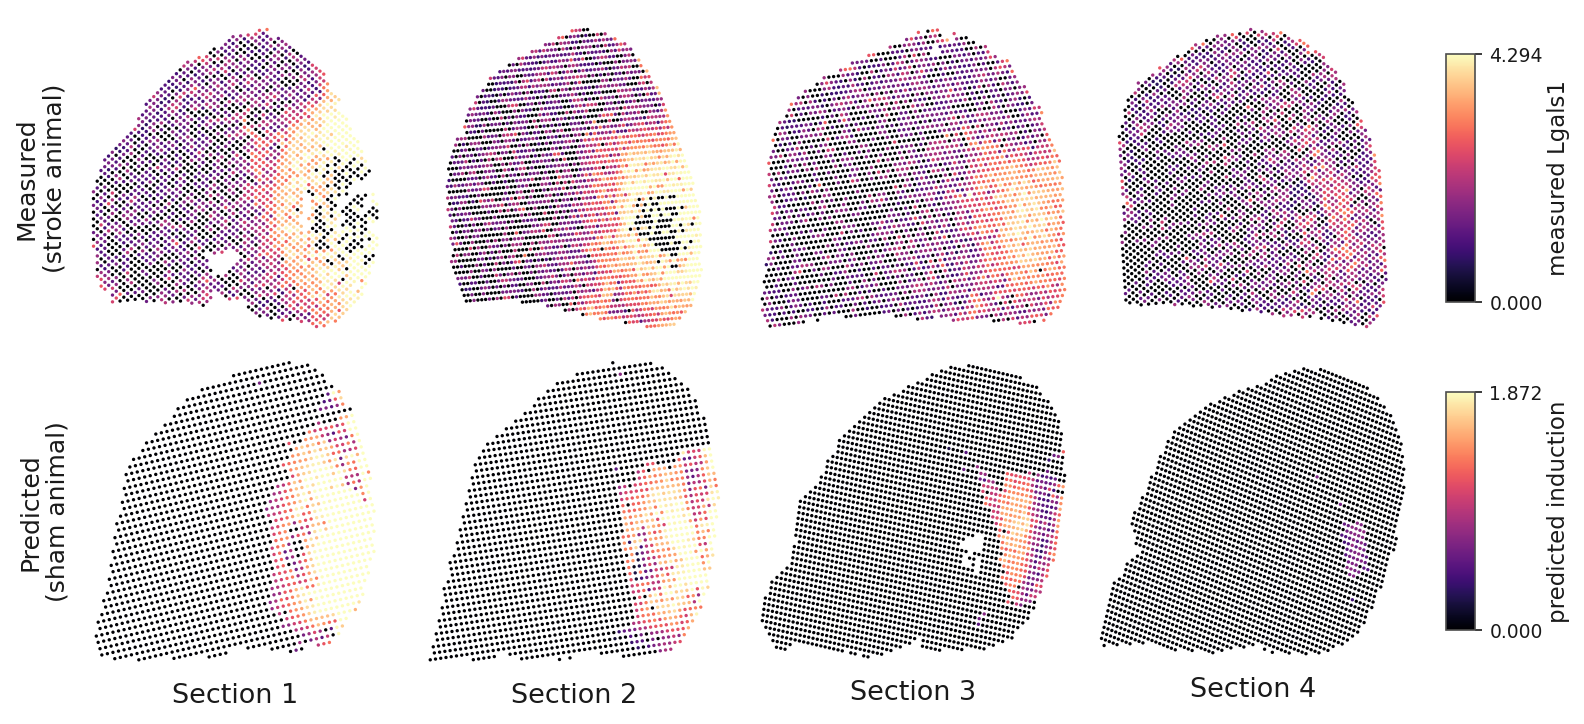

In [6]:
for gene in SPATIAL_GENES:
    spatial_figure("3d", gene); plt.show()

## Where things are

| | |
|---|---|
| model source | `models/concert_spac_niche/` |
| prep, figures, diagnostics | `experiments/07_stroke_case_study/` |
| the figure this notebook follows | `experiments/07_stroke_case_study/figures/plot_core_rim_patch.py` |
| checkpoints and decodes | `checkpoints/stroke_{2d,3d}_core_rim/`, `data/stroke/decodes_{2d,3d}/` |